In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv('/Users/marcosbautista/Documents/GitHub/Estimation-of-epidemiological-parameters/Datos/COVID19MEXICO2020_2021_2022_2023.csv')

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20372904 entries, 0 to 20372903
Data columns (total 28 columns):
 #   Column                 Dtype
---  ------                 -----
 0   FECHA_ACTUALIZACION    str  
 1   ID_REGISTRO            str  
 2   SEXO                   int64
 3   TIPO_PACIENTE          int64
 4   FECHA_INGRESO          str  
 5   FECHA_SINTOMAS         str  
 6   FECHA_DEF              str  
 7   INTUBADO               int64
 8   NEUMONIA               int64
 9   EDAD                   int64
 10  NACIONALIDAD           int64
 11  DIABETES               int64
 12  EPOC                   int64
 13  ASMA                   int64
 14  INMUSUPR               int64
 15  HIPERTENSION           int64
 16  OTRA_COM               int64
 17  CARDIOVASCULAR         int64
 18  OBESIDAD               int64
 19  RENAL_CRONICA          int64
 20  TABAQUISMO             int64
 21  OTRO_CASO              int64
 22  TOMA_MUESTRA_LAB       int64
 23  RESULTADO_LAB          int64
 24  TOMA_MU

In [6]:
# Null Values  
null_values = df.isnull().sum()
print(null_values)

FECHA_ACTUALIZACION      0
ID_REGISTRO              0
SEXO                     0
TIPO_PACIENTE            0
FECHA_INGRESO            0
FECHA_SINTOMAS           0
FECHA_DEF                0
INTUBADO                 0
NEUMONIA                 0
EDAD                     0
NACIONALIDAD             0
DIABETES                 0
EPOC                     0
ASMA                     0
INMUSUPR                 0
HIPERTENSION             0
OTRA_COM                 0
CARDIOVASCULAR           0
OBESIDAD                 0
RENAL_CRONICA            0
TABAQUISMO               0
OTRO_CASO                0
TOMA_MUESTRA_LAB         0
RESULTADO_LAB            0
TOMA_MUESTRA_ANTIGENO    0
RESULTADO_ANTIGENO       0
CLASIFICACION_FINAL      0
UCI                      0
dtype: int64


In [7]:
# Data columns to data types
data_columns = ["FECHA_ACTUALIZACION","FECHA_INGRESO","FECHA_SINTOMAS","FECHA_DEF"]
for col in data_columns:
    df[col] = pd.to_datetime(df[col], errors='coerce')
print(df.dtypes)

FECHA_ACTUALIZACION      datetime64[us]
ID_REGISTRO                         str
SEXO                              int64
TIPO_PACIENTE                     int64
FECHA_INGRESO            datetime64[us]
FECHA_SINTOMAS           datetime64[us]
FECHA_DEF                datetime64[us]
INTUBADO                          int64
NEUMONIA                          int64
EDAD                              int64
NACIONALIDAD                      int64
DIABETES                          int64
EPOC                              int64
ASMA                              int64
INMUSUPR                          int64
HIPERTENSION                      int64
OTRA_COM                          int64
CARDIOVASCULAR                    int64
OBESIDAD                          int64
RENAL_CRONICA                     int64
TABAQUISMO                        int64
OTRO_CASO                         int64
TOMA_MUESTRA_LAB                  int64
RESULTADO_LAB                     int64
TOMA_MUESTRA_ANTIGENO             int64


/var/folders/sl/_0vv98412kq54qbqdd087ztw0000gn/T/ipykernel_11479/575987917.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[col] = pd.to_datetime(df[col], errors='coerce')


In [8]:
# Sorted Values
df = df.sort_values(by='FECHA_INGRESO', ascending=True)
df.reset_index(drop=True, inplace=True)

In [9]:
# Duplicate Values

duplicated = df.duplicated().sum()
print(f"Number of duplicated rows: {duplicated}")

Number of duplicated rows: 0


In [14]:
df.describe()

,FECHA_ACTUALIZACION,SEXO,TIPO_PACIENTE,FECHA_INGRESO,FECHA_SINTOMAS,FECHA_DEF,INTUBADO,NEUMONIA,EDAD,NACIONALIDAD,...,OBESIDAD,RENAL_CRONICA,TABAQUISMO,OTRO_CASO,TOMA_MUESTRA_LAB,RESULTADO_LAB,TOMA_MUESTRA_ANTIGENO,RESULTADO_ANTIGENO,CLASIFICACION_FINAL,UCI
count,20372904,2.037290e+07,2.037290e+07,20372904,20372904,445190,2.037290e+07,2.037290e+07,2.037290e+07,2.037290e+07,...,2.037290e+07,2.037290e+07,2.037290e+07,2.037290e+07,2.037290e+07,2.037290e+07,2.037290e+07,2.037290e+07,2.037290e+07,2.037290e+07
mean,2022-10-27 00:14:25.272109,1.457122e+00,1.072250e+00,2021-09-20 13:02:12.605308,2021-09-17 21:17:05.350141,2021-03-12 13:38:16.757790,9.020476e+01,2.958564e+00,3.823824e+01,1.006997e+00,...,2.355727e+00,2.436068e+00,2.394203e+00,4.866786e+00,1.684527e+00,6.693809e+01,1.296876e+00,2.995716e+01,5.399026e+00,9.020673e+01
min,2021-10-31 00:00:00,1.000000e+00,1.000000e+00,2020-01-01 00:00:00,2020-01-01 00:00:00,2020-01-02 00:00:00,1.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,...,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
25%,2022-08-09 00:00:00,1.000000e+00,1.000000e+00,2021-02-06 00:00:00,2021-02-04 00:00:00,2020-09-03 00:00:00,9.700000e+01,2.000000e+00,2.600000e+01,1.000000e+00,...,2.000000e+00,2.000000e+00,2.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,1.000000e+00,2.000000e+00,3.000000e+00,9.700000e+01
50%,2022-08-09 00:00:00,1.000000e+00,1.000000e+00,2021-09-03 00:00:00,2021-08-31 00:00:00,2021-01-20 00:00:00,9.700000e+01,2.000000e+00,3.600000e+01,1.000000e+00,...,2.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00,9.700000e+01,1.000000e+00,2.000000e+00,7.000000e+00,9.700000e+01
75%,2023-06-01 00:00:00,2.000000e+00,1.000000e+00,2022-02-15 00:00:00,2022-02-13 00:00:00,2021-08-17 00:00:00,9.700000e+01,2.000000e+00,5.000000e+01,1.000000e+00,...,2.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00,9.700000e+01,2.000000e+00,9.700000e+01,7.000000e+00,9.700000e+01
max,2024-05-17 00:00:00,2.000000e+00,2.000000e+00,2024-04-19 00:00:00,2023-12-31 00:00:00,2024-03-07 00:00:00,9.900000e+01,9.900000e+01,2.660000e+02,2.000000e+00,...,9.800000e+01,9.800000e+01,9.800000e+01,9.900000e+01,2.000000e+00,9.700000e+01,2.000000e+00,9.700000e+01,7.000000e+00,9.900000e+01
std,NaN,4.981581e-01,2.589020e-01,NaN,NaN,NaN,2.449723e+01,9.807070e+00,1.745667e+01,8.335631e-02,...,6.477806e+00,6.526068e+00,6.583861e+00,1.731408e+01,4.647038e-01,4.428414e+01,4.568813e-01,4.356542e+01,1.983544e+00,2.449055e+01


CLASIFICACION_FINAL
7    11791076
3     7319704
6      757457
1      377706
5       98902
2       15995
4       12064
Name: count, dtype: int64


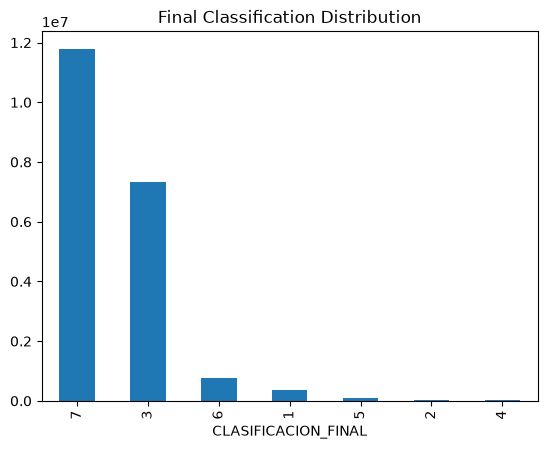

In [18]:
# Final clasification
df['CLASIFICACION_FINAL'].value_counts().plot(kind='bar', title='Final Classification Distribution')
print(df['CLASIFICACION_FINAL'].value_counts())

In [ ]:
# number of positive cases 

positive_cases = df[
    df['CLASIFICACION_FINAL'].isin([1,2,3])
].copy()


In [22]:
positive_cases

,FECHA_ACTUALIZACION,ID_REGISTRO,SEXO,TIPO_PACIENTE,FECHA_INGRESO,FECHA_SINTOMAS,FECHA_DEF,INTUBADO,NEUMONIA,EDAD,...,OBESIDAD,RENAL_CRONICA,TABAQUISMO,OTRO_CASO,TOMA_MUESTRA_LAB,RESULTADO_LAB,TOMA_MUESTRA_ANTIGENO,RESULTADO_ANTIGENO,CLASIFICACION_FINAL,UCI
22215,2021-10-31,044a42,2,1,2020-02-27,2020-02-23,NaT,97,2,59,...,2,2,2,1,1,1,2,97,3,97
22219,2021-10-31,05f3d3,2,2,2020-02-27,2020-02-22,NaT,2,1,36,...,2,2,1,1,1,1,2,97,3,1
22220,2021-10-31,135d2f,2,1,2020-02-27,2020-02-22,NaT,97,2,41,...,2,2,2,1,1,1,2,97,3,97
22395,2021-10-31,09b2c0,1,1,2020-02-27,2020-02-27,NaT,97,2,27,...,2,2,2,2,2,97,2,97,1,97
22854,2021-10-31,189846,2,1,2020-02-28,2020-02-19,NaT,97,2,45,...,2,2,2,1,1,1,2,97,3,97
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20372724,2024-05-17,gbc2d28,1,1,2024-01-04,2023-12-31,NaT,97,2,68,...,2,2,2,1,1,1,2,97,3,97
20372814,2024-05-17,g90c4a1,2,2,2024-01-05,2023-12-31,NaT,2,1,0,...,2,2,2,1,1,1,2,97,3,2
20372848,2024-05-17,gd761c9,2,2,2024-01-07,2023-12-31,NaT,2,1,82,...,2,2,2,99,1,1,2,97,3,2
20372883,2024-05-17,g553dec,2,2,2024-01-10,2023-12-30,2024-01-29,1,1,77,...,2,2,2,1,1,1,2,97,3,1


In [24]:
# number of deaths

deaths = positive_cases[
    positive_cases['FECHA_DEF'].notna()
].copy()
deaths     

,FECHA_ACTUALIZACION,ID_REGISTRO,SEXO,TIPO_PACIENTE,FECHA_INGRESO,FECHA_SINTOMAS,FECHA_DEF,INTUBADO,NEUMONIA,EDAD,...,OBESIDAD,RENAL_CRONICA,TABAQUISMO,OTRO_CASO,TOMA_MUESTRA_LAB,RESULTADO_LAB,TOMA_MUESTRA_ANTIGENO,RESULTADO_ANTIGENO,CLASIFICACION_FINAL,UCI
23039,2021-10-31,9b6ba5,2,2,2020-02-29,2020-02-29,2021-01-03,2,2,38,...,2,2,2,2,2,97,2,97,1,2
23798,2021-10-31,014225,1,2,2020-03-02,2020-03-02,2020-04-27,2,2,69,...,1,1,2,99,1,1,2,97,3,2
24112,2021-10-31,1c0fa3,2,2,2020-03-03,2020-03-02,2020-04-25,1,1,55,...,2,1,2,2,2,97,2,97,2,2
25149,2021-10-31,0d06cc,1,2,2020-03-04,2020-03-04,2020-04-02,2,1,57,...,1,2,2,99,1,1,2,97,3,2
25263,2021-10-31,16c986,1,2,2020-03-04,2020-03-04,2020-04-04,2,1,52,...,1,2,2,1,1,4,2,97,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20368580,2024-05-17,g96c49c,2,2,2023-12-26,2023-12-22,2024-01-02,2,1,17,...,2,2,2,2,1,1,2,97,3,2
20369273,2024-05-17,gc8d5f5,2,2,2023-12-27,2023-12-22,2023-12-28,2,1,41,...,2,2,2,2,1,1,2,97,3,2
20371200,2024-05-17,gd74fdc,2,2,2023-12-30,2023-12-30,2024-01-07,1,1,72,...,1,2,2,99,1,1,2,97,3,2
20371957,2024-05-17,gdffcbf,2,2,2024-01-02,2023-12-30,2024-01-03,2,1,68,...,2,2,1,2,1,1,2,97,3,2


In [25]:
print(f"Number of positive cases: {len(positive_cases)}")
print(f"Number of deaths: {len(deaths)}")

Number of positive cases: 7713405
Number of deaths: 335098
